---
title: "Complete static and feedback QPE accounting"
---

This executed companion reads the retained new synthesis and physical records.
Native factory queries run in the bounded producer, once per task/variant.
The target is the known phase .3 of P(2πφ), explicitly prepared with X.
Fifteen fresh complete runs estimate a scalar median within 2^-m.
The phase lies away from the branch cut for both m=3 and4.
These are conditional engineering scenarios and ideal numerical checks,
not hardware results or a formal confidence certificate.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / "src/openquantum").is_dir():
    root = root.parent
sys.path.insert(0, str(root / "src"))
folder = root / "assets/generated/qpe-feedback-resources"
reports = [json.loads((folder / f"n1-m{m}/report.json").read_text()) for m in (3, 4)]
reports[0]["task"]

{'phase': 0.3,
 'phase_bits': 3,
 'repetitions': 15,
 'operator_error_allowance': 2e-05,
 'physical_failure_budget': 0.0025,
 'factory_availability_budget': 0.0025,
 'target_qubits': 1,
 'output': 'scalar median of15 decoded y/2**m estimates',
 'absolute_phase_error_target': 0.125,
 'phase_branch_cut_condition': '2**(-m) <= phi <=1-2**(-m)',
 'ideal_single_run_good_probability_lower_bound': 0.8105694691387022,
 'ideal_majority_failure_upper_bound': 0.0029684634290533004,
 'synthesis_full_workload_tv_upper_estimate': 0.00030000000000000003,
 'conditional_failure_upper_estimate': 0.0082684634290533,
 'confidence_status': 'ideal theorem plus numerical synthesis and conditional physical scenarios; no hardware/formal confidence certificate',
 'fresh_complete_preparations': 15,
 'stored_transcript_bits': 45,
 'controlled_unitary_calls_per_run': 7,
 'median_controller_decisions_all_runs': 676,
 'classical_processing': '15*m bit decoding slots,105 fixed bubble-network comparators each with m b

The executable source retains explicit startup initialization, each round reset,
all repeated controlled calls, intermediate readouts and actual predicates.
The target survives every round. Its code exposure is charged during the full
factory, reset, measurement and feedback schedule.

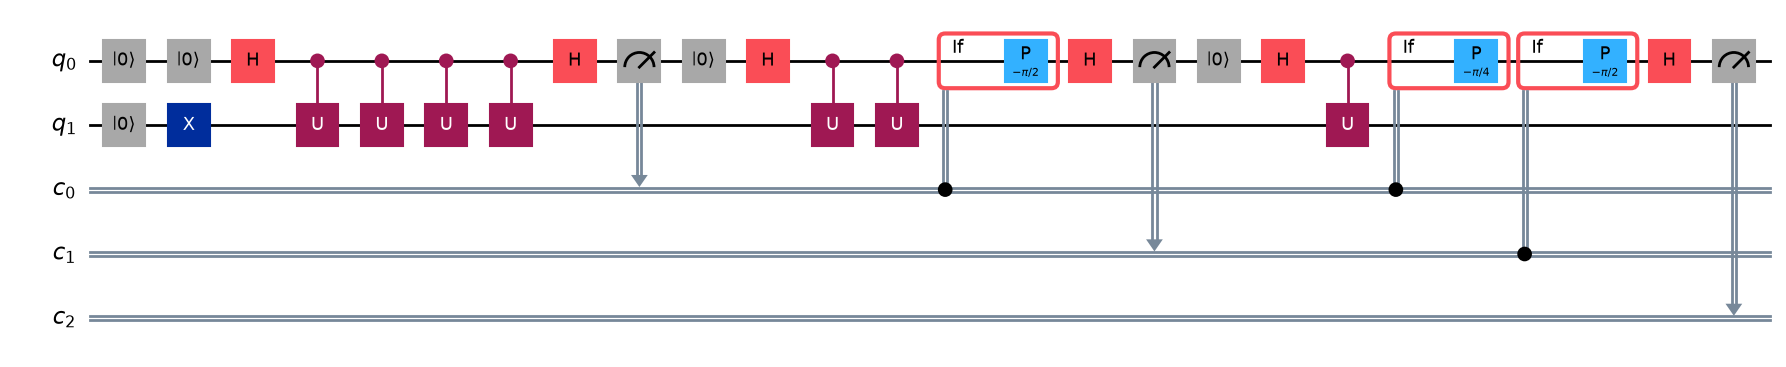

In [2]:
#| label: qpe-feedback-physical-circuit
from openquantum.qpe_feedback_resources import PhaseTask, build_sources
build_sources(PhaseTask(phase_bits=3))["feedback"].draw("mpl", fold=100, cregbundle=False)

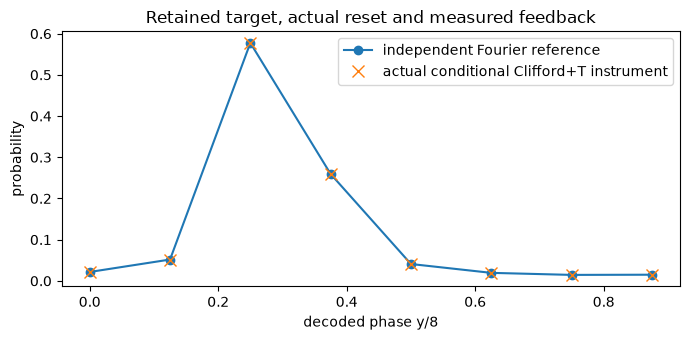

Removing all corrections changes the largest probability by 0.37298711269877516


In [3]:
#| label: qpe-feedback-physical-probabilities
import numpy as np
report = reports[0]
x = np.arange(8) / 8
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, report["independent_fourier_probabilities"], "o-", label="independent Fourier reference")
ax.plot(x, report["checks"]["feedback"]["clifford_t_probabilities"], "x", markersize=8, label="actual conditional Clifford+T instrument")
ax.set(xlabel="decoded phase y/8", ylabel="probability", title="Retained target, actual reset and measured feedback")
ax.legend()
fig.tight_layout()
plt.show()
print("Removing all corrections changes the largest probability by", report["feedback_removed_max_error"])

In [4]:
#| label: qpe-feedback-physical-table
pd.read_csv(folder / "summary.csv")

,target_qubits,phase_bits,variant,phase_error_target,complete_runs,data_code_distance,peak_physical_qubits,capped_runtime_all_runs_seconds,full_physical_failure_model,factory_availability_failure_model,actual_t_and_tdg_per_run_upper_bound
0,1,3,textbook,0.1250,15,11,8435,165.908225,0.000255,0.000611,4074
1,1,3,feedback,0.1250,15,11,6507,90.592058,0.000068,0.000443,2954
2,1,4,textbook,0.0625,15,11,9399,394.159777,0.000764,0.001344,8958
3,1,4,feedback,0.0625,15,11,6507,205.908351,0.000155,0.001011,6742


The table selects the smallest computed physical-qubit point per task/variant;
complete Pareto points remain in the reports. Every feedback point provisions
one distance, factory configuration and retry cap for all allowed transcripts.
Skipped correction slots retain their full idle time. Predicate decisions are
charged even when false; no branch-specific machine or expected runtime saving
is used. Both variants share the frozen physical task and model.

Startup workspace, explicit input preparation, actual controlled access,
concrete synthesis, T injection/transport, factory retries, reset/readout and
controller fault scenarios are included. Geometry, tracked Pauli bases,
encoder/decoder and handoff remain conditional assumptions. The fixed15-sample scalar median network is charged once after all runs,
including controller faults and reserved-patch exposure. Offline compilation
and presentation-only final reporting time are excluded. The existing static
mean-fit QPE projection and Grover baseline have not been repriced.

In [5]:
feedback = reports[0]["physical"]["feedback"]
point = min(feedback["pareto_points"], key=lambda p: p["peak_physical_qubits"])
print("Same padded machine for all", len(feedback["branch_coverage"]["allowed_transcripts"]), "transcripts")
print("Distance:", point["data_code_distance"], "factory:", point["factory_supply"])
pd.DataFrame.from_dict(point["failure_components_all_attempts"], orient="index", columns=["full15-run model contribution"])

Same padded machine for all 8 transcripts
Distance: 11 factory: {'output_error': 3.521300000000001e-11, 'pipeline_time_ns': 143000, 'fixed_logical_distillation_distance': 11, 'native_qec_crossing_prefactor': 0.03, 'native_qec_threshold': 0.01, 'native_code_cycle_time_ns': 1000, 'quality_calibration_scope': 'QDK factory model; distinct from the Litinski per-cycle data-exposure fit', 'full_pipeline_retry_cap_per_state': 4, 'states_all_complete_attempts': 44310, 'worst_case_pipeline_attempts': 177240, 'availability_failure_union_bound': 0.0004431, 'retry_cap_arithmetic': 'exact Fraction search over decimal input strings; smallest cap in 1..16', 'pipeline_feedback_rounds_reserved': 3, 'extra_init_readout_feedback_dispatch_ns_per_pipeline': 41800, 'extra_output_port_hold_ns_per_state': 675100}


,full15-run model contribution
data_workspace_code_exposure,6.341444e-05
factory_output_handoff_storage,2.995356e-06
logical_readout_scenario,6.720935e-10
logical_initialization_scenario,1.615815e-07
controller_scenario,3.793396e-09
factory_output_quality_model,1.560288e-06


The complete reports, source/synthesized QASM and branch ledgers are under
assets/generated/qpe-feedback-resources. The all-corrections QASM is explicitly
accounting input, not the executable feedback circuit. Qiskit2.6.2 is
Apache-2.0; rsgridsynth0.2.2 and QDK1.34.0 are MIT. The producer records exact
source/package identities, saved sequence hashes and synthesis wall time.

Scalable phase-product source ledgers at n=1,2,4,8 are separate and unvalidated
at the extra widths. This feedback physical adapter supports n=1,m≤4 only.